# Lecture 8 – Getting data from APIs

QSS 20 · Modern Statistical Computing · Fall 2026

### Agenda

- Send an HTTP request and read the response.
- JSON, and how it differs from a Python dictionary.
- File paths with `pathlib`.
- Query parameters, a silent row limit, and pages.
- API keys in a `.env` file.
- Save the raw response and a record of the request.

## Where we left off

- Last lecture, every table was a file in `data/raw/`. Someone had already
  collected the Florida voters and the Census surnames and saved them.
- Much of the data social scientists use is not a file that you download
  once. It sits on another organization's server, it changes every day, and
  it is too large to copy whole.

- Today you ask that server for the rows you need, check what comes back, and
  save it so that you can repeat the analysis.

### Setup: install once

This lecture adds two packages: `requests` sends HTTP requests, and
`python-dotenv` reads API keys from a file. Install them once, in a terminal,
not in this notebook:

```bash
conda activate qss20
conda install requests python-dotenv
```

- `conda activate qss20` makes the course environment the active one, so
  `conda install` puts the packages there. Type `y` when conda asks to
  proceed.
- If an import in the next cell still fails, restart the kernel
  (Kernel → Restart Kernel) and run it again.

### Setup: imports and folders

In [1]:
import json
import os
import time
from datetime import datetime, timezone
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import requests
from dotenv import load_dotenv

pd.set_option('display.max_rows', 8)

# Sharp figures on high-resolution screens, from lecture 6.
%config InlineBackend.figure_format = 'retina'
# Show only the last line of an error message.
%xmode Minimal

RAW = Path('../../data/raw')    # saved copies, read by every table
LIVE = Path('../../data/live')  # today's requests, ignored by Git
LIVE.mkdir(exist_ok=True)

Exception reporting mode: Minimal


- Every import sits in this one cell. `json`, `os`, `time`, `datetime`, and
  `pathlib` come with Python.
- The last three lines name two folders and make sure that `data/live/`
  exists.

### ❓ Question

```python
RAW = Path('../../data/raw')
RAW / 'pokemon' / 'pikachu.json'
```

Python's `/` divides numbers. What is the output here: a number, an error, or
something else?

<details><summary>Answer</summary>

**A path:** `PosixPath('../../data/raw/pokemon/pikachu.json')` on a Mac, and
`WindowsPath(...)` on Windows. `RAW` is a path object, not a string. Between a
path and a string, `/` joins them into a longer path.

</details>

### File paths with `pathlib`

In [2]:
RAW, type(RAW)

(PosixPath('../../data/raw'), pathlib.PosixPath)

In [3]:
RAW / 'pokemon' / 'pikachu.json'

PosixPath('../../data/raw/pokemon/pikachu.json')

- `Path` comes from `pathlib`, part of Python's standard library. It turns a
  string into a **path object** that knows the rules for file names.
- Python lets each type decide what an operator does. `+` adds numbers and
  joins strings; `/` divides numbers and joins paths. A path writes the right
  separator for your system: `/` on macOS, `\` on Windows.
- `..` means the folder above. This notebook is in `lectures/lec08/`, so
  `../../` is the top of the course folder.

| Write | Job |
|---|---|
| `p.exists()` | `True` if the file or folder is there |
| `p.read_text(encoding='utf-8')` | read a whole file into one string |
| `p.write_text(s, encoding='utf-8')` | write a string to a file |
| `p.mkdir(exist_ok=True)` | make a folder; no error if it is there |
| `folder.glob('*.json')` | every file whose name fits the pattern |
| `p.name` | the file name without the folders |

- `read_text` opens the file, reads it, and closes it, in one line. Lecture 6
  opened a file with `with open(...) as f:`. You still need `with open` to
  read a large file line by line, or to hand an open file to a function.
- Pass `encoding='utf-8'` each time. Without it, Python 3.12 on Windows uses
  an older encoding that fails on characters such as `é`.

## How a program asks a server for data

- A **server** is a computer that holds data and answers requests. A
  **client** is the program that asks: your browser, or Python.
- The client sends a **request**, and the server sends back a **response**.
  **HTTP**, the protocol of the web, sets the rules for both.

![A client on the left sends a GET request for the URL https://pokeapi.co/api/v2/pokemon/pikachu to a server on the right. The server sends back a response with three parts: a status code, 200 OK; headers, such as Content-Type application/json; and a body, the text of the data](images/request-response.png)

## What is an API?

- An **API** (application programming interface) is a list of requests that
  one program may send to another, with a description of the answer to each.
  The provider writes the list and publishes it as **documentation**.
- The term is broader than the web. pandas has an API too: its functions and
  their arguments. Today's APIs are **web APIs**. The requests travel over
  HTTP, and the answers are text, most often JSON.

- The provider keeps its database private. You ask for what the API offers;
  the provider's server runs the query and sends back the result.
- Behind the API, the provider can move or rebuild its database, require a
  key, or limit how often you ask. The URLs that your code uses stay the same.

## A first API: Pokémon

- [PokeAPI](https://pokeapi.co) serves data from the Pokémon video games. It
  is free, needs no key, and its answers are small and stable, so you can see
  each step.

<img src="images/api-pokeapi.png" width="480" alt="The PokeAPI home page. A box holds the request https://pokeapi.co/api/v2/pokemon/ditto. Below it, the answer for Ditto appears as a tree: id 132, name ditto, height 3, weight 40, then a list of abilities whose first entry, limber, has its own URL">

- What is inside, on 2026-10-08: 1,351 Pokémon (1,025 species and their
  alternate forms), 937 moves, 374 abilities, 2,223 items, and 21 types, from
  9 generations of games.
- Each kind of thing has its own endpoint, 51 in all: `pokemon`, `type`,
  `move`, `ability`, `item`, and more. An answer links to other answers: the
  ability `limber` above has its own URL.

### The parts of a URL

| Part | In `https://pokeapi.co/api/v2/pokemon?limit=5&offset=10` |
|---|---|
| Scheme | `https` |
| Host, the server | `pokeapi.co` |
| Path, the resource | `/api/v2/pokemon` |
| Query string, the options | `?limit=5&offset=10` |

- The query string starts with `?`. Each option is `key=value`, and `&`
  separates options. This URL asks for 5 Pokémon, after skipping the first
  10.

- An API calls its URLs **endpoints**. PokeAPI puts the choice of Pokémon in
  the **path**, as in `/api/v2/pokemon/pikachu`, and the options for a list in
  the **query string**. Other APIs put most choices in the query string.

### Request methods and status codes

- **GET** asks for a resource. **POST** sends data to the server, such as a
  form or a message to a chatbot. Every request today is a GET.
- Every response starts with a three-digit **status code**. The first digit
  gives the class.

| Code | Meaning |
|---|---|
| `200` | OK: here is what you asked for |
| `301`, `302` | Moved: look at another URL |
| `400` | Bad request: the server cannot read what you sent |
| `401`, `403` | Not allowed: missing key, or no permission |
| `404` | Not found |
| `429` | Too many requests: slow down |
| `500`, `503` | The server failed |

### What the documentation tells you

| Question | PokeAPI's [documentation](https://pokeapi.co/docs/v2) |
|---|---|
| Which endpoints exist? | 51, listed at `https://pokeapi.co/api/v2/` |
| Which parameters? | a list takes `limit` and `offset` |
| What shape is the answer? | each field, with its type: `weight` is an integer, in hectograms |
| Do you need a key? | no |
| How much at a time? | a list sends 20 results unless you set `limit` |
| What are the terms? | the [fair use policy](https://pokeapi.co/docs/v2#fairuse): save a local copy of what you request |

- Read the documentation before your first request, and again when a result
  looks wrong. Each API in this lecture has its own documentation, linked
  where the API first appears.

### Send a GET request

In [4]:
res = requests.get('https://pokeapi.co/api/v2/pokemon/pikachu', timeout=30)
res

<Response [200]>

- `requests.get(url)` sends the request and waits for the response.
  `<Response [200]>` means that the server answered with status 200, OK.
- `timeout=30` stops the wait after 30 seconds. Without it, a slow server can
  freeze your notebook.

### What came back

In [5]:
res.status_code, res.headers['Content-Type'], len(res.text)

(200, 'application/json; charset=utf-8', 305177)

In [6]:
type(res.text), res.text[:120]

(str,
 '{"id":25,"name":"pikachu","base_experience":112,"height":4,"is_default":true,"order":35,"weight":60,"abilities":[{"is_hi')

- `res.headers` describes the response. `Content-Type` says that the body is
  JSON.
- `res.text` is the body: one `str` of about 300,000 characters. It looks like
  a Python dictionary, but it is text. `res.text[:120]` slices characters, and
  `res.text['name']` fails, because a string has positions, not keys.

## JSON

- **JSON** (JavaScript Object Notation) is a text format for nested data.
  It started in JavaScript. Python, R, and most other languages read and write
  it, so most APIs send it.
- JSON has two containers. An **object** holds `"key": value` pairs in
  braces; an **array** holds values in square brackets. Each can hold the
  other, to any depth.

```json
{"name": "pikachu", "weight": 60, "legendary": false,
 "types": ["electric"], "nickname": null}
```

### JSON text and a Python dictionary

- They look alike: braces, `key: value` pairs, square brackets for lists, and
  nesting.
- One is text, and the other is a Python value. JSON is **text**: a string
  that travels over the network or sits in a file. A dictionary lives in your
  computer's memory, with keys that you can look up.
- `json.loads` turns JSON text into Python objects (*load* from a *string*).
  `json.dumps` turns Python objects into JSON text (*dump* to a *string*).

In [7]:
text = ('{"name": "pikachu", "weight": 60, "legendary": false, '
        '"types": ["electric"], "nickname": null}')
d = json.loads(text)
type(text), type(d)

(str, dict)

In [8]:
d['name'], d['legendary'], d['nickname'], d['types']

('pikachu', False, None, ['electric'])

- The object became a `dict` and the array became a `list`. `false` became
  `False`, and `null` became `None`.

### JSON types and Python types

| JSON | Example | Python |
|---|---|---|
| object | `{"name": "pikachu", "weight": 60}` | `dict` |
| array | `[35, 55, 40]` | `list` |
| string | `"electric"` | `str` |
| number | `60`, `0.5` | `int`, `float` |
| `true` / `false` | `true` | `True` / `False` |
| `null` | `null` | `None` |

- JSON writes strings and keys in **double quotes** only, and every key is a
  string.
- JSON has no tuples, sets, dates, or comments. A date travels as a string,
  such as `"2021-03-14"`.

### ❓ Question

```python
json.loads("{'name': 'pikachu'}")
```

`{'name': 'pikachu'}` is a valid Python dictionary. What does `json.loads` do
with it?

<details><summary>Answer</summary>

**It raises an error, `JSONDecodeError`.** JSON requires double quotes around
strings and keys. Single quotes are fine in Python and invalid in JSON. Text
that Python prints for a dictionary is not always valid JSON.

</details>

### From Python to JSON and back

In [9]:
json.loads("{'name': 'pikachu'}")

JSONDecodeError: Expecting property name enclosed in double quotes: line 1 column 2 (char 1)

In [10]:
json.dumps({1: 'one', 'ok': True, 'missing': None, 'pair': (1, 2)})

'{"1": "one", "ok": true, "missing": null, "pair": [1, 2]}'

- `json.dumps` writes double quotes, `true`, and `null`. The key `1` became
  the string `"1"`, and the tuple became an array.
- Read back with `json.loads`, the dictionary has the key `'1'` and a list.
  A trip through JSON can change types, so check them after you parse.

### The shape of the Pikachu response

![A tree of the Pikachu response. The top is a dictionary with keys such as name, weight, types, stats, and moves. types is a list with one element, a dictionary with keys slot and type; type is a dictionary whose name is electric. stats is a list of six dictionaries, each with base_stat, effort, and a stat dictionary whose name is hp, attack, and so on](images/pikachu-json.png)

In [11]:
pikachu = res.json()
type(pikachu), len(pikachu)

(dict, 21)

In [12]:
list(pikachu.keys())

['id',
 'name',
 'base_experience',
 'height',
 'is_default',
 'order',
 'weight',
 'abilities',
 'past_abilities',
 'forms',
 'game_indices',
 'held_items',
 'location_area_encounters',
 'moves',
 'species',
 'sprites',
 'cries',
 'stats',
 'past_stats',
 'types',
 'past_types']

- `res.json()` does the same as `json.loads(res.text)`: here it returns a
  `dict` with 21 keys.

### ❓ Question

```python
pikachu['types']
```

```
[{'slot': 1, 'type': {'name': 'electric',
  'url': 'https://pokeapi.co/api/v2/type/13/'}}]
```

What is the output of `pikachu['types'][0]['type']['name']`?

<details><summary>Answer</summary>

**`'electric'`.** `pikachu['types']` is a list, so `[0]` takes its first
element, a dictionary. `['type']` is another dictionary, and `['name']` is a
string. Each step uses the index that fits the object: a position for a list,
a key for a dictionary.

</details>

### Walk down a path

In [13]:
pikachu['types'][0]['type']['name']

'electric'

In [14]:
type(pikachu['stats']), len(pikachu['stats']), pikachu['stats'][0]

(list,
 6,
 {'base_stat': 35,
  'effort': 0,
  'stat': {'name': 'hp', 'url': 'https://pokeapi.co/api/v2/stat/1/'}})

- Read a response from the outside in. At each level, print the keys of a
  dictionary or the length of a list, then step one level down.
- `pikachu['stats']` is a list of six dictionaries, one per base stat. This
  list is the repeated part of the response, and repeated parts become rows.

### Save what the server sent

In [15]:
(LIVE / 'pikachu.json').write_text(res.text, encoding='utf-8')

305177

- `LIVE / 'pikachu.json'` is the path `../../data/live/pikachu.json`.
  `.write_text` writes the string to that file and returns the number of
  characters it wrote.
- Save the body as text, before any parsing. If your analysis goes wrong, you
  can parse the saved copy again without another request.
- `data/raw/pokemon/` holds the copy saved for this lecture on 2026-10-08.
  From here on, the lecture reads saved copies, so it gives the same results
  tomorrow.

In [16]:
path = RAW / 'pokemon' / 'pikachu.json'
pikachu = json.loads(path.read_text(encoding='utf-8'))
pikachu['name'], pikachu['weight']

('pikachu', 60)

### A path segment picks the resource

In [17]:
water = requests.get('https://pokeapi.co/api/v2/type/water', timeout=30).json()
weak_to = water['damage_relations']['double_damage_from']
len(water['pokemon']), [t['name'] for t in weak_to]

(192, ['grass', 'electric'])

- Change the path from `/pokemon/pikachu` to `/type/water`, and the server
  returns a different resource with a different shape. 192 Pokémon have the
  water type. Grass and electric attacks do double damage to them.
- The documentation lists the keys of each endpoint's response: see
  [Pokémon](https://pokeapi.co/docs/v2#pokemon) and
  [Types](https://pokeapi.co/docs/v2#types). Read it, or print the keys,
  before you write a path.

### ❓ Question

```python
bad = requests.get('https://pokeapi.co/api/v2/pokemon/wolverine', timeout=30)
bad.status_code
```

Wolverine is not a Pokémon. What is the status code, and can `bad.json()`
still return something?

<details><summary>Answer</summary>

**404, and yes.** The server answers "not found", and it writes its error
messages as JSON too: `{'status': 404, 'message': 'Not Found'}`. A parsed body
does not mean that you got Pikachu. Check the status code first.

</details>

### A missing resource

In [18]:
bad = requests.get('https://pokeapi.co/api/v2/pokemon/wolverine', timeout=30)
bad.status_code, bad.json()

(404, {'status': 404, 'message': 'Not Found'})

In [19]:
bad.raise_for_status()

HTTPError: 404 Client Error: Not Found for url: https://pokeapi.co/api/v2/pokemon/wolverine

- `raise_for_status()` does nothing after a 200. After a 4xx or 5xx code it
  stops the code with an `HTTPError`, so a failed request cannot turn into an
  empty or wrong table without a warning.

<div class="alert alert-info">

**Key idea.** Before you parse a response, check its status code and content
type. Turn a response into data only when it is a 200 and the type you expect.

</div>

<div class="alert alert-success">

### Activity · Pikachu's base stats

`pikachu['stats']` is a list of six dictionaries. Build a DataFrame with one
row per stat and two columns, `stat` (such as `'hp'`) and `base_stat`. Then
sort it so that the highest stat comes first.

Start from one element: print `pikachu['stats'][0]` and find the path to each
value before you write a loop or a list comprehension.

</div>

### One row per stat

In [20]:
stats = pd.DataFrame([
    {'stat': s['stat']['name'], 'base_stat': s['base_stat']}
    for s in pikachu['stats']
])
stats.sort_values('base_stat', ascending=False)

,stat,base_stat
5,speed,90
1,attack,55
3,special-attack,50
4,special-defense,50
2,defense,40
0,hp,35


- The list comprehension builds one dictionary per element. `pd.DataFrame`
  turns a list of dictionaries into rows, with the keys as columns.
- Pikachu's highest stat is `speed`, 90. Most API responses become tables in
  this way: find the list of records, then make one row per record.

## Traffic deaths in New York City

- In 2014 New York City set out to end deaths on its streets. The city called
  the plan Vision Zero.
- Speed cameras near schools issued their first tickets in January 2014, and
  140 school zones had cameras by June. On 7 November 2014 the default speed
  limit fell from 30 to 25 mph. The city also redesigned dangerous streets.
- The city's reason for the lower limit: a pedestrian struck at 25 mph is half
  as likely to die as one struck at 30 mph.

> **Did traffic deaths in New York City fall after 2014, and for whom?**

- The police report every crash, and the city publishes the reports online.

### Where the records live: NYC Open Data

<img src="images/api-nyc-catalog.png" width="760" alt="The NYC Open Data catalog page. It reports 3020 results and offers filters by view type, such as datasets, maps, and files, and by category, such as business, city government, education, environment, and health. The first listed dataset is For Hire Vehicles (FHV) - Active, in the transportation category">

- [NYC Open Data](https://opendata.cityofnewyork.us/) is the city's portal
  for data that its agencies publish. On 2026-10-08 its catalog listed 3,020
  items, 2,404 of them datasets.
- Examples: 311 service requests since 2020, restaurant inspection results
  from the Health Department, the 2015 street tree census from the Parks
  Department, and NYPD arrests.
- Each dataset has its own endpoint, and every endpoint takes the same query
  parameters. Code that you write for one dataset works on the others.

### [The crash records](https://dev.socrata.com/foundry/data.cityofnewyork.us/h9gi-nx95)

<img src="images/api-nyc-crashes.png" width="700" alt="The top of the dataset page Motor Vehicle Collisions - Crashes, category Public Safety, data provided by the Police Department (NYPD). A note says that the dataset is temporarily not updating while its automated update process is fixed">

- New York police file a report (form MV104-AN) for every crash that injures
  or kills someone or causes at least \$1,000 of damage. The city publishes
  **one row per reported crash**, from July 2012 on, with 29 columns: date,
  time, place, the numbers injured and killed, causes, and vehicle types.

- The table holds 2,269,187 crashes. Few of them kill anyone. An API lets a
  program ask for the deadly ones only, instead of a download of 2 million
  rows.
- Read the note at the top. The city's daily updates stopped while it fixes
  them, and the data were last updated on 15 June 2026. Check a dataset's
  dates before you call it current.

### The same data, for people and for programs

| | A page for people | An API for programs |
|---|---|---|
| Open it | [the dataset page](https://data.cityofnewyork.us/Public-Safety/Motor-Vehicle-Collisions-Crashes/h9gi-nx95) | [two rows from the API](https://data.cityofnewyork.us/resource/h9gi-nx95.json?%24limit=2) |
| You get | a table with menus and buttons | the rows as JSON, nothing else |
| You pick rows by | clicking filters | writing parameters in the URL |
| Next month, you | click the same filters again | send the same URL again |

- The endpoint is `https://data.cityofnewyork.us/resource/h9gi-nx95.json`.
  The [API page](https://dev.socrata.com/foundry/data.cityofnewyork.us/h9gi-nx95)
  lists the fields that it returns.
- It needs no key for light use. Requests without an
  [app token](https://dev.socrata.com/docs/app-tokens.html) share one limit
  per IP address. Students on campus Wi-Fi may share one address, and so
  one limit.

In [21]:
nyc_url = 'https://data.cityofnewyork.us/resource/h9gi-nx95.json'

### ❓ Question

```python
res = requests.get(nyc_url, timeout=60)
rows = res.json()
len(rows)
```

The city holds 2,269,187 crash records. How many rows come back?

<details><summary>Answer</summary>

**1,000.** This API sends 1,000 rows and stops if you do not say how many you
want. It raises no error and prints no warning. The response is a 200 and
looks complete. The documentation for
[`$limit`](https://dev.socrata.com/docs/queries/limit.html) states the
default: 1,000 records per request.

</details>

### A silent limit

In [22]:
res = requests.get(nyc_url, timeout=60)
rows = res.json()
res.status_code, type(rows), len(rows)

(200, list, 1000)

- 1,000 of 2,269,187 records is 0.04 percent. A table built from this
  response would hold 1,000 crashes in no useful order, and nothing would
  look broken.
- Many APIs send results one **page** at a time. Read the documentation for
  the default page size, and count what you received.

### Where to find the parameters

- The crash records have their own API documentation:
  [dev.socrata.com/foundry/data.cityofnewyork.us/h9gi-nx95](https://dev.socrata.com/foundry/data.cityofnewyork.us/h9gi-nx95).
  Scroll to **Fields**. It lists every column's API name and type, such as
  `number_of_persons_killed` (number). These names go inside the parameters.
- The parameters belong to SoQL, the query language of Socrata, the software
  behind NYC Open Data. [SoQL queries](https://dev.socrata.com/docs/queries/) documents each one on its own
  page: [`$where`](https://dev.socrata.com/docs/queries/where.html), [`$select`](https://dev.socrata.com/docs/queries/select.html),
  [`$order`](https://dev.socrata.com/docs/queries/order.html), [`$group`](https://dev.socrata.com/docs/queries/group.html),
  [`$limit`](https://dev.socrata.com/docs/queries/limit.html), [`$offset`](https://dev.socrata.com/docs/queries/offset.html).

- The examples on the crash documentation use version 3 of the API, released
  in 2025: their URLs contain `/api/v3/` and an
  [app token](https://dev.socrata.com/docs/app-tokens.html). Today's URLs end
  in `/resource/h9gi-nx95.json`. They use
  [version 2.1](https://dev.socrata.com/docs/endpoints.html), which answers
  without a token. The field names are the same in both.

### The column names

<img src="images/api-nyc-columns.png" width="760" alt="The Columns (29) table on the crash dataset page, with four columns: Column Name, Description, API Field Name, and Data Type. For example, NUMBER OF PERSONS KILLED has the API field name number_of_persons_killed and the type Number; CRASH DATE has crash_date, a floating timestamp">

- The dataset page shows the same names in its table "Columns (29)". Use the
  API field name, such as `number_of_persons_killed`, in `$where` and
  `$select`. The column name on the left is for people.

### Query parameters

- This API takes options in the query string. Its query language, SoQL, uses
  names that start with `$`. Field names come from the
  [crash API documentation](https://dev.socrata.com/foundry/data.cityofnewyork.us/h9gi-nx95), under **Fields**.

| Parameter | Job |
|---|---|
| `$where` | keep the rows that meet a condition |
| `$select` | choose columns, or compute new ones |
| `$order` | sort the rows |
| `$limit`, `$offset` | how many rows, starting after how many |

- Pass the options as a dictionary to `params=`. `requests` writes the query
  string.

In [23]:
params = {
    '$where': 'number_of_persons_killed > 0',
    '$select': 'collision_id, crash_date, borough, number_of_persons_killed',
    '$order': 'collision_id',
    '$limit': 5,
}
res = requests.get(nyc_url, params=params, timeout=60)
res.url

'https://data.cityofnewyork.us/resource/h9gi-nx95.json?%24where=number_of_persons_killed+%3E+0&%24select=collision_id%2C+crash_date%2C+borough%2C+number_of_persons_killed&%24order=collision_id&%24limit=5'

- `res.url` is the URL that `requests` sent. A URL cannot hold spaces, `$`,
  or `>`, so `requests` wrote them as `+`, `%24`, and `%3E`. Print `res.url`
  first when a request misbehaves.

In [24]:
pd.DataFrame(res.json())

,collision_id,crash_date,borough,number_of_persons_killed
0,516,2012-08-23T00:00:00.000,MANHATTAN,1
1,1303,2012-11-26T00:00:00.000,NaN,1
2,3610,2013-08-21T00:00:00.000,MANHATTAN,1
3,4421,2013-11-22T00:00:00.000,MANHATTAN,1
4,6184,2012-11-06T00:00:00.000,MANHATTAN,1


- `$where` kept only crashes with at least one death, and `$select` kept four
  columns.
- Every value is text, even `number_of_persons_killed`. This API writes
  numbers and dates as JSON strings, so convert them before any arithmetic.

### ❓ Question

3,469 crashes killed at least one person. A loop asks for 1,000 rows per
request, moves `$offset` forward by the rows it received, and stops at the
first request that returns no rows.

How many requests does the loop send, and how many rows does the last
non-empty page hold?

<details><summary>Answer</summary>

**5 requests; 469 rows.** Pages 1 to 3 hold 1,000 rows each, and page 4 holds
469. The fifth request, at offset 3,469, returns an empty list, and the loop
stops there.

</details>

### Pages: `$limit` and `$offset`

- Ask for the 3,469 fatal crashes 1,000 at a time. `$offset` skips the rows
  already received.

In [25]:
offset, page = 0, 1
while True:
    params = {'$where': 'number_of_persons_killed > 0',
              '$order': 'collision_id', '$limit': 1000, '$offset': offset}
    res = requests.get(nyc_url, params=params, timeout=60)
    res.raise_for_status()
    rows = res.json()
    if len(rows) == 0:
        break
    path = LIVE / f'fatal-crashes-page-{page}.json'
    path.write_text(res.text, encoding='utf-8')
    print('page', page, 'offset', offset, 'rows', len(rows))
    offset, page = offset + len(rows), page + 1
    time.sleep(1)

page 1 offset 0 rows 1000


page 2 offset 1000 rows 1000


page 3 offset 2000 rows 1000


page 4 offset 3000 rows 469


- The loop stops at the first empty page. `$order` fixes the order of the
  rows, so the pages do not overlap or skip rows.
- `time.sleep(1)` waits one second between requests. A script can send
  requests much faster than a person clicks, and the pause keeps the load on
  the server small.
- The loop saves each page as it arrives. If request 3 fails, pages 1 and 2
  are already on disk.

<div class="alert alert-info">

**Key idea.** A response from an API is often one page of a longer list. Find
out how many rows exist, keep asking until you have them all, and count what
you saved.

</div>

### Read the saved pages

- `data/raw/nyc/` holds the pages that this loop saved on 2026-10-08, with 16
  columns chosen by `$select`.

In [26]:
pages = sorted((RAW / 'nyc').glob('fatal-crashes-page-*.json'))
[p.name for p in pages]

['fatal-crashes-page-1.json',
 'fatal-crashes-page-2.json',
 'fatal-crashes-page-3.json',
 'fatal-crashes-page-4.json']

In [27]:
crashes = pd.DataFrame([row for p in pages
                        for row in json.loads(p.read_text(encoding='utf-8'))])
len(crashes), crashes['collision_id'].nunique()

(3469, 3469)

- `glob` finds every file whose name fits the pattern, and `sorted` puts them
  in page order. The comprehension reads each page and pools its rows.
- 3,469 rows and 3,469 distinct `collision_id` values: one row per fatal
  crash, and no crash appears twice.

In [28]:
crashes[['crash_date', 'borough', 'on_street_name']].head(3)

,crash_date,borough,on_street_name
0,2012-08-23T00:00:00.000,MANHATTAN,BROAD STREET
1,2012-11-26T00:00:00.000,NaN,NaN
2,2013-08-21T00:00:00.000,MANHATTAN,WEST HOUSTON STREET


- A record leaves out a field that has no value, so the DataFrame shows `NaN`
  there. 1,368 of these crashes have no borough. Lecture 10 returns to that
  gap.

### Let the server count

In [29]:
params = {
    '$select': 'date_extract_y(crash_date) AS year, count(*) AS crashes, '
               'sum(number_of_persons_killed) AS killed, '
               'sum(number_of_pedestrians_killed) AS pedestrians, '
               'sum(number_of_cyclist_killed) AS cyclists, '
               'sum(number_of_motorist_killed) AS motorists',
    '$group': 'year',
    '$order': 'year',
}
res = requests.get(nyc_url, params=params, timeout=180)
res.status_code, len(res.json())

(200, 15)

- The server grouped 2,269,187 records by year and sent back 15 rows. The
  `$select` text is close to SQL, the language of lecture 10.
- The server reads every record to answer, so this request can take one or
  two minutes, and `timeout=180` allows for that. If you cannot wait, skip
  it: the next cell reads the copy saved on 2026-10-08.

In [30]:
text = (RAW / 'nyc' / 'deaths-by-year.json').read_text(encoding='utf-8')
deaths = pd.DataFrame(json.loads(text)).astype(int)
deaths

,year,crashes,killed,pedestrians,cyclists,motorists
0,2012,100545,137,72,6,59
1,2013,203742,297,176,11,110
2,2014,206046,262,133,20,109
3,2015,217708,243,133,15,95
...,...,...,...,...,...,...
11,2023,96607,280,107,31,123
12,2024,91316,268,124,24,111
13,2025,85546,229,119,23,81
14,2026,36424,68,43,11,30


- `crashes` counts every reported crash, deadly or not. `killed` counts
  people. The saved copy is the same query, run on 2026-10-08.
- One crash can kill more than one person: in 2013, 284 fatal crashes killed
  297 people. To count people, sum the column that counts people.

### ❓ Question

| year | killed | pedestrians | cyclists | motorists |
|---|---|---|---|---|
| 2013 | 297 | 176 | 11 | 110 |
| 2021 | 297 | 132 | 19 | 134 |

Deaths in 2021 equal deaths in 2013. Did nothing change?

<details><summary>Answer</summary>

**The parts changed.** 44 fewer pedestrians died in 2021 than in 2013. 24 more
motorists and 8 more cyclists died, and 12 deaths in 2021 fall in none of the
three columns.

</details>

## Did deaths fall after 2014?

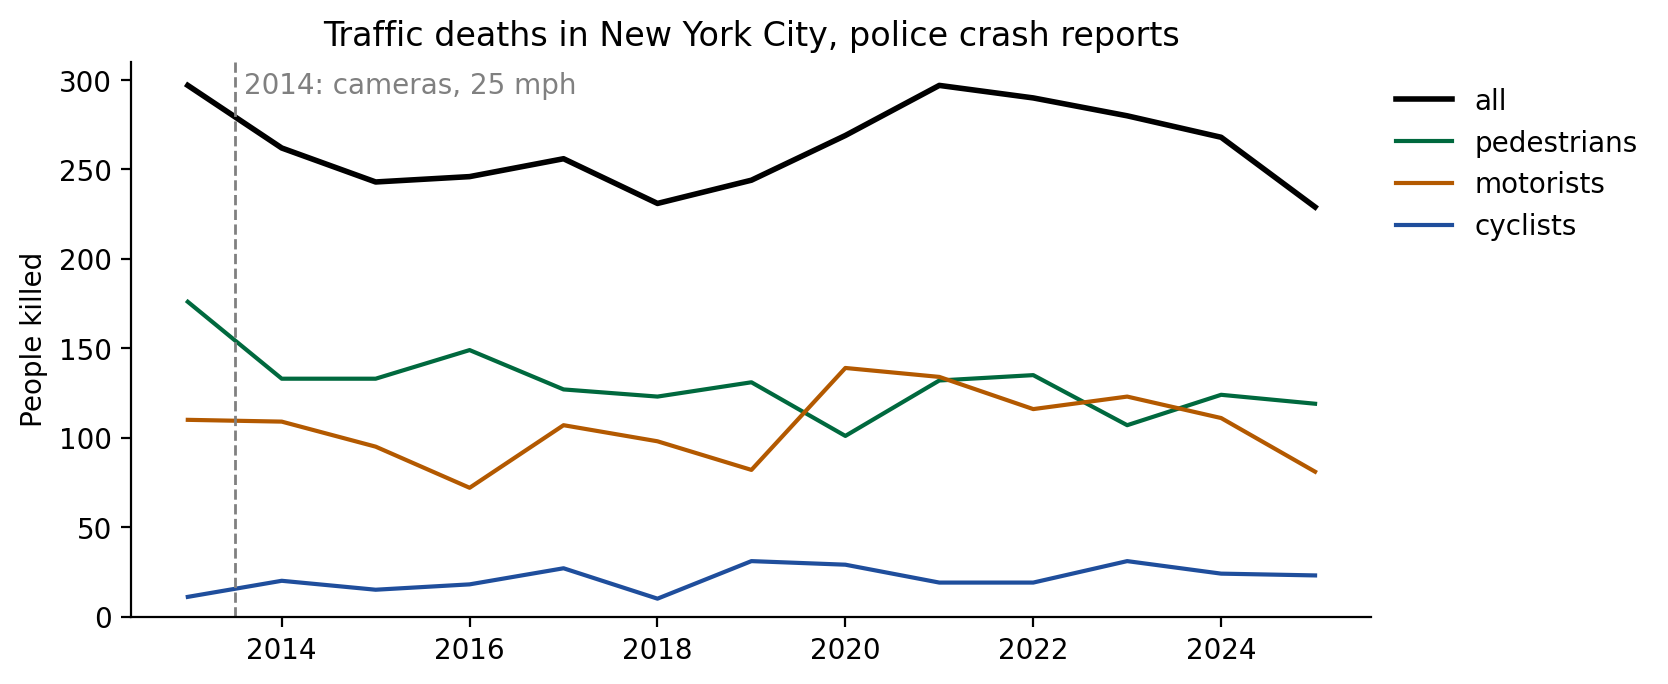

In [31]:
full = deaths.loc[deaths['year'].between(2013, 2025)].set_index('year')

fig, ax = plt.subplots(figsize=(8, 3.6))
ax.plot(full.index, full['killed'], color='black', lw=2, label='all')
ax.plot(full.index, full['pedestrians'], color='#00693e', label='pedestrians')
ax.plot(full.index, full['motorists'], color='#b35900', label='motorists')
ax.plot(full.index, full['cyclists'], color='#1f4e9c', label='cyclists')
ax.axvline(2013.5, color='grey', ls='--', lw=1)
ax.text(2013.6, 305, '2014: cameras, 25 mph', color='grey', va='top')
ax.set(ylim=(0, 310), ylabel='People killed',
       title='Traffic deaths in New York City, police crash reports')
ax.legend(loc='upper left', bbox_to_anchor=(1, 1), frameon=False)
ax.spines[['top', 'right']].set_visible(False);

- The plot leaves out 2012 and 2026: the records start in July 2012, and this
  snapshot ends in May 2026. A partial year would look like a drop.
- All deaths: 297 in 2013, 231 in 2018, back to 297 in 2021, and 229 in 2025.
- Pedestrians: **176** in 2013, and between 101 and 149 in every year since.
- Motorists: between 72 and 110 a year from 2013 to 2019, then 139 in 2020
  and 134 in 2021. Reported crashes fell by half in 2020, while deaths inside
  vehicles rose.

- The three columns do not always add up to `killed`. In 2021, 12 deaths fall
  in none of them; in 2017 the columns sum to 5 more than `killed`. Lecture
  10's table of persons shows who those people were.

## What we found

- Pedestrian deaths fell after 2013 and stayed lower in every year since.
- All traffic deaths did not stay lower. They returned to the 2013 level in
  2021, as deaths of people inside vehicles rose.

- What these data cannot show:
  - The records start in July 2012, so 2013 is the only full year before
    2014. One year cannot show the trend before the changes.
  - Deaths can change for many reasons: the pandemic, traffic volume, new
    vehicles such as e-bikes. A before-and-after comparison in one city cannot
    separate the city's 2014 changes from those.
  - The counts come from police reports as filed. Check the city's own
    published totals before you cite a number.

### Compared with what?

- A flat or falling line means little alone. If deaths rose across the United
  States after 2014, New York's numbers look better; if they fell everywhere,
  worse.
- A web page lists national traffic deaths for every year in one table.
  Lecture 9 collects them with a scraper.

## APIs that need a key

- **New question:** how much does a 30-year home mortgage cost now, compared
  with 2021?
- **New source:** FRED, the Federal Reserve Economic Data.
- **What stays the same:** `requests.get`, `params`, the status code, JSON.
- **What changes:** FRED wants to know who is asking. Every request must carry
  an **API key**, a password issued to you.

### Find the series: search FRED

<img src="images/api-fred-search.png" width="760" alt="FRED search results for 30-year mortgage rate: 42 series. The first result is 30-Year Fixed Rate Mortgage Average in the United States, percent, weekly, not seasonally adjusted, from 1971-04-02 to 2026-10-01. The second is the 30-Year Fixed Rate Veterans Affairs Mortgage Index, percent, daily, from 2017-01-03">

- [FRED](https://fred.stlouisfed.org) (Federal Reserve Economic Data) has
  collected economic time series since 1991, from government agencies, central
  banks, and organizations such as Freddie Mac.
- The API asks for a series by its ID, so find the ID first. Type plain words
  into FRED's search box: "30-year mortgage rate" matches 42 series.
- Compare the results by units, frequency, and dates. The first is a weekly
  average back to 1971. The second is a daily index that starts in 2017.

### One series: `MORTGAGE30US`

<img src="images/api-fred.png" width="460" alt="The FRED page for the series 30-Year Fixed Rate Mortgage Average in the United States, MORTGAGE30US. A breadcrumb places it under Categories, Money, Banking, and Finance, Interest Rates, Mortgage Rates. The latest observation is 7.28 percent on 2026-10-01; units are percent, not seasonally adjusted; frequency is weekly, ending Thursday; the chart runs from 1971-04-02, with a peak above 18 percent in the early 1980s">

- The series page shows the ID in parentheses after the title:
  `MORTGAGE30US`. Every series has one, such as `UNRATE` (unemployment),
  `CPIAUCSL` (consumer prices), and `GDP`.
- The [API](https://fred.stlouisfed.org/docs/api/fred/) groups its endpoints by category, release, series,
  source, and tag. [`series/search`](https://fred.stlouisfed.org/docs/api/fred/series_search.html) runs the same
  search from code, and
  [`series/observations`](https://fred.stlouisfed.org/docs/api/fred/series_observations.html) returns the dated
  values of one series.

### A request without a key

In [32]:
fred_url = 'https://api.stlouisfed.org/fred/series/observations'
params = {'series_id': 'MORTGAGE30US', 'file_type': 'json'}
res = requests.get(fred_url, params=params, timeout=30)
res.status_code, res.json()

(400,
 {'error_code': 400,
  'error_message': 'Bad Request.  Variable api_key is not set.  Read https://fred.stlouisfed.org/docs/api/api_key.html for more information.'})

- **400**, bad request. The error body is JSON too, and it names what is
  missing: the variable `api_key`.

### Get a key and store it in `.env`

1. Create a free FRED account and request an API key
   ([instructions](https://fred.stlouisfed.org/docs/api/api_key.html)). The
   error message links to the same page.
2. In a terminal, go to the top of the course folder and copy the template:
   `cp .env.example .env` (in the Windows Command Prompt, `copy` instead of
   `cp`)
3. Open `.env` in a text editor, such as VS Code. Replace `your-key-here` with
   your key, so the line reads `FRED_API_KEY=` and then the key.

- A `.env` file holds one `NAME=value` line per secret. Names that start with
  a dot are hidden in Finder, File Explorer, and the JupyterLab file browser.
  The terminal and VS Code show them.

### Keep the key out of Git

- A key in a notebook travels with every copy, commit, screenshot, and prompt
  that you paste into an AI tool. If a key leaks, revoke it and request a new
  one.
- `.env` holds your secrets and stays on your computer. `.env.example` holds
  placeholders and goes into Git, so others know which keys to get.
- The course folder's `.gitignore` already lists `.env`. In a terminal,
  `git check-ignore .env` prints `.env` if Git ignores the file.
- In your own projects, add a line `.env` to `.gitignore` **before** your
  first commit. Git keeps every committed file in its history, even after you
  delete the file.

### Read the key in Python

- `load_dotenv` comes from `python-dotenv`, which the setup cells installed
  and imported.

In [33]:
load_dotenv(Path('../../.env'))

True

- `load_dotenv(path)` copies each `NAME=value` line of the file into the
  **environment variables** of this Python session. It returns `True` if it
  found a variable, and `False` if the file is missing or empty.
- It does not replace a variable that is already set.

In [34]:
key = os.environ.get('FRED_API_KEY')

if key is None:
    print('FRED_API_KEY is not set. Follow the steps for .env above.')
else:
    params = {'search_text': '30-year mortgage rate', 'limit': 5,
              'file_type': 'json', 'api_key': key}
    res = requests.get('https://api.stlouisfed.org/fred/series/search',
                       params=params, timeout=30)
    found = pd.DataFrame(res.json()['seriess'])
    display(found[['id', 'title', 'frequency']])

,id,title,frequency
0,MORTGAGE30US,30-Year Fixed Rate Mortgage Average in the Uni...,"Weekly, Ending Thursday"
1,OBMMIVA30YF,30-Year Fixed Rate Veterans Affairs Mortgage I...,Daily
2,OBMMIJUMBO30YF,30-Year Fixed Rate Jumbo Mortgage Index,Daily
3,OBMMIFHA30YF,30-Year Fixed Rate FHA Mortgage Index,Daily
4,OBMMIC30YF,30-Year Fixed Rate Conforming Mortgage Index,Daily


- `os.environ.get` returns `None` when the variable is not set, so the cell
  prints a message instead of failing.
- With a key, `series/search` returns the website's search as data: one row
  per series, with its `id`. FRED names the list `seriess`, with two s's.
- `display` shows a DataFrame as a table from inside an `if` block, where a
  last line would not print.

status: 200


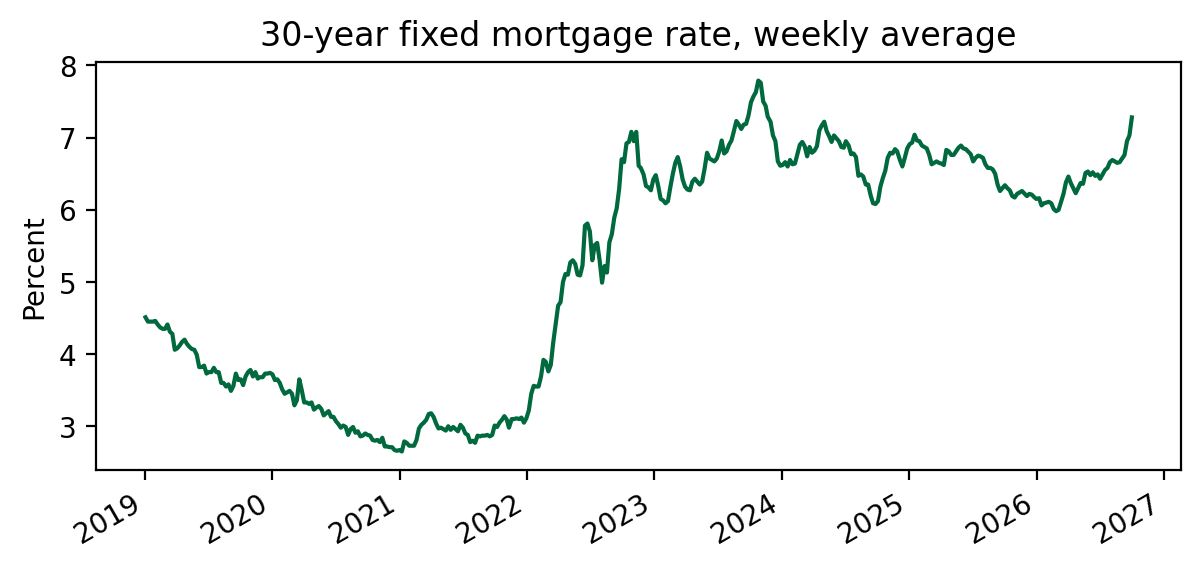

In [35]:
if key is None:
    print('FRED_API_KEY is not set. Follow the steps for .env above.')
else:
    params = {'series_id': 'MORTGAGE30US', 'file_type': 'json',
              'observation_start': '2019-01-01', 'api_key': key}
    res = requests.get(fred_url, params=params, timeout=30)
    print('status:', res.status_code)
    rates = pd.DataFrame(res.json()['observations'])
    rates = rates.assign(date=pd.to_datetime(rates['date']),
                         rate=pd.to_numeric(rates['value'], errors='coerce'))
    ax = rates.plot(x='date', y='rate', legend=False, figsize=(7, 3),
                    color='#00693e')
    ax.set(xlabel='', ylabel='Percent',
           title='30-year fixed mortgage rate, weekly average')

- The code prints the status, not `res.url`: the URL now contains the key.
- The answer: the rate averaged 2.96 percent in 2021, with a low of 2.65. It
  peaked at 7.79 percent in October 2023 and was 7.28 percent on 1 October
  2026, about two and a half times the 2021 average.

## Save what you collect, and how

- A collection that others can check keeps three layers:
  1. the **raw** response bodies, as the server sent them;
  2. a **source record**: the URL with its parameters, the time (UTC), and
     the status;
  3. the **derived** tables, built by code from the raw files.

In [36]:
path = RAW / 'nyc' / 'source-record.json'
record = json.loads(path.read_text(encoding='utf-8'))
first = record['files'][1]
record['source'], first['file'], first['status'], first['retrieved_at_utc']

('NYC Open Data, Motor Vehicle Collisions: Crashes (https://data.cityofnewyork.us/d/h9gi-nx95), Persons (f55k-p6yu), and Vehicles (bm4k-52h4)',
 'fatal-crashes-page-1.json',
 200,
 '2026-10-08T00:05:19Z')

- With the raw pages and this record, anyone can rebuild `crashes`, or send
  the same request again and see what changed since 2026-10-08.
- Pause between requests, save responses instead of asking twice, and follow
  the provider's terms and rate limits. A `429` means that you asked too
  fast.

In [37]:
stamp = datetime.now(timezone.utc).isoformat(timespec='seconds')
(LIVE / 'retrieved-at-utc.txt').write_text(stamp, encoding='utf-8')
stamp

'2026-10-08T07:08:46+00:00'

- `datetime.now(timezone.utc)` is the current time in UTC, the same in every
  time zone. Record it when you save a response.
- `res.text` is the body decoded as text, and `res.content` is the same body
  as bytes. `Path.write_bytes(res.content)` saves the exact bytes that the
  server sent, which is the safer choice for HTML pages.

### The MLB Stats API

<img src="images/api-mlb-docs.png" width="560" alt="The entry Endpoint: teams_stats in the volunteer MLB-StatsAPI wiki. URL: https://statsapi.mlb.com/api/{ver}/teams/stats. Required parameters: season + group + stats. All parameters: ver, season, sportIds, group, gameType, stats, order, sortStat, fields, startDate, endDate. Note: use meta('statGroups') to look up valid values for group, and meta('statTypes') for valid values for stats">

- Major League Baseball's Stats API, at `statsapi.mlb.com`, serves MLB's
  game, player, and team records as JSON. It needs no key.
- The [endpoint list](https://github.com/toddrob99/MLB-StatsAPI/wiki/Endpoints) above documents 64 endpoints: schedules, box
  scores and play-by-play for each game, standings, rosters, players,
  transactions, the draft, attendance, and season statistics.
- The entry shown is the activity's endpoint, `teams_stats`: its URL, its
  required parameters, and where to look up their values.

### Unofficial documentation

- PokeAPI, NYC Open Data, and FRED each document their own API. The
  organization that runs the server writes the documentation, and the
  documentation describes what that server promises to do.
- MLB runs `statsapi.mlb.com`, but its own documentation site asks for a
  login. The endpoint list comes from the wiki of
  [MLB-StatsAPI](https://github.com/toddrob99/MLB-StatsAPI/wiki/Endpoints), a Python package that volunteers keep on GitHub.
  The wiki says so itself:

> "This information is provided for reference only, without warranty or guarantee, and is not official documentation provided by MLB. This package and its author are not affiliated with MLB or any MLB team."

- MLB has no part in the wiki, and it can change or remove an endpoint
  without telling the wiki's authors. The endpoint page was last edited on
  26 March 2025.
- Use unofficial documentation to find endpoints and parameters, then check
  each detail against what the server returns: print the keys, and compare a
  value you know.

## Activity notebook: did MLB's 2023 rules raise stolen bases?

- **New question:** in 2023 Major League Baseball added a pitch clock, limited
  pickoff throws, and enlarged the bases. Did base runners steal more?
- **New row unit:** one team in one season, from the MLB Stats API.
- **What stays the same:** an endpoint with `params`, nested JSON, a loop that
  pauses and saves one file per request, then a table from the saved files.
- **What changes:** the 2020 season had 60 games instead of 162, so the
  denominator matters.
- Open `lec08_activity.ipynb`. It starts with a check that the API works: the
  Padres' most recent game.

## Summary

| Goal | Write |
|---|---|
| Send a GET request | `res = requests.get(url, params=..., timeout=30)` |
| Check the response | `res.status_code`, `res.headers['Content-Type']` |
| Stop on a failed request | `res.raise_for_status()` |
| See the URL that was sent | `res.url` |
| Body as text | `res.text` |
| JSON text to Python, and back | `res.json()`, `json.loads(text)`, `json.dumps(obj)` |
| Build a file path | `Path('../../data/raw') / 'nyc' / 'page-1.json'` |
| Save the body before parsing | `path.write_text(res.text, encoding='utf-8')` |
| Time of retrieval, in UTC | `datetime.now(timezone.utc).isoformat()` |
| Read a saved JSON file | `json.loads(path.read_text(encoding='utf-8'))` |
| List of records to rows | `pd.DataFrame([{...} for r in records])` |
| Find saved files | `sorted(folder.glob('page-*.json'))` |
| Text to numbers | `s.astype(int)`, `pd.to_numeric(s, errors='coerce')` |
| Pause between requests | `time.sleep(1)` |
| Read a key from `.env` | `load_dotenv(Path('../../.env'))`, then `os.environ.get('NAME')` |